In [4]:
import pandas as pd

df = pd.read_csv('/content/shopping_trends.csv')

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 3900
Columns: 19


In [5]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

In [7]:
df.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [10]:
for column in df.columns:
    print(column, ":", df[column].nunique())

Customer ID : 3900
Age : 53
Gender : 2
Item Purchased : 25
Category : 4
Purchase Amount (USD) : 81
Location : 50
Size : 4
Color : 25
Season : 4
Review Rating : 26
Subscription Status : 2
Payment Method : 6
Shipping Type : 6
Discount Applied : 2
Promo Code Used : 2
Previous Purchases : 50
Preferred Payment Method : 6
Frequency of Purchases : 7


In [11]:
df.select_dtypes(include=['number']).columns

Index(['Customer ID', 'Age', 'Purchase Amount (USD)', 'Review Rating',
       'Previous Purchases'],
      dtype='object')

In [12]:
df.select_dtypes(include=['object']).columns

Index(['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color',
       'Season', 'Subscription Status', 'Payment Method', 'Shipping Type',
       'Discount Applied', 'Promo Code Used', 'Preferred Payment Method',
       'Frequency of Purchases'],
      dtype='object')

In [13]:
df['Customer_Category'] = pd.qcut(
    df['Purchase Amount (USD)'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

df['Customer_Category'].value_counts()

,count
Customer_Category,
Medium,1303
Low,1300
High,1297


In [14]:
df[['Purchase Amount (USD)', 'Customer_Category']].head(10)

,Purchase Amount (USD),Customer_Category
0,53,Medium
1,64,Medium
2,73,Medium
3,90,High
4,49,Medium
5,20,Low
6,85,High
7,34,Low
8,97,High
9,31,Low


In [15]:
features = [
    'Age',
    'Previous Purchases',
    'Review Rating',
    'Frequency of Purchases',
    'Subscription Status'
]

X = df[features]
y = df['Customer_Category']

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   Age  Previous Purchases  Review Rating Frequency of Purchases  \
0   55                  14            3.1            Fortnightly   
1   19                   2            3.1            Fortnightly   
2   50                  23            3.1                 Weekly   
3   21                  49            3.5                 Weekly   
4   45                  31            2.7               Annually   

  Subscription Status  
0                 Yes  
1                 Yes  
2                 Yes  
3                 Yes  
4                 Yes  

Target:
0    Medium
1    Medium
2    Medium
3      High
4    Medium
Name: Customer_Category, dtype: category
Categories (3, object): ['Low' < 'Medium' < 'High']


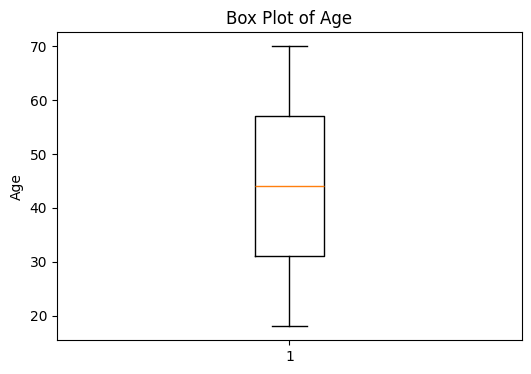

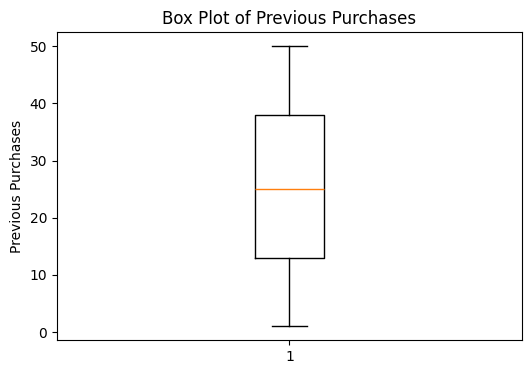

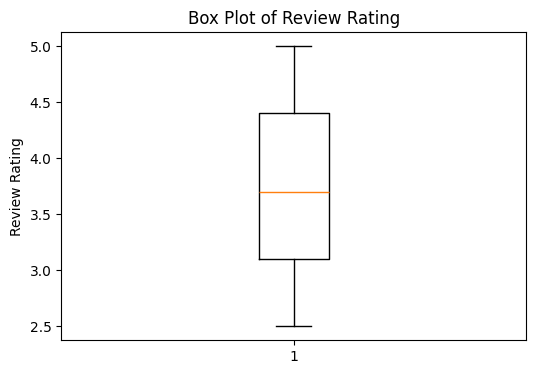

In [16]:
import matplotlib.pyplot as plt

numerical_features = [
    'Age',
    'Previous Purchases',
    'Review Rating'
]

for feature in numerical_features:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.ylabel(feature)
    plt.show()

In [17]:
print("Frequency of Purchases:")
print(df['Frequency of Purchases'].unique())

print("\nSubscription Status:")
print(df['Subscription Status'].unique())

Frequency of Purchases:
['Fortnightly' 'Weekly' 'Annually' 'Quarterly' 'Bi-Weekly' 'Monthly'
 'Every 3 Months']

Subscription Status:
['Yes' 'No']


In [18]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_features = [
    'Age',
    'Previous Purchases',
    'Review Rating'
]

categorical_features = [
    'Frequency of Purchases',
    'Subscription Status'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3120, 5)
Testing data: (780, 5)


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        multi_class='multinomial'
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Model training completed successfully!


In [21]:
y_pred = model.predict(X_test)

print("First 10 Actual Categories:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Categories:")
print(y_pred[:10])

First 10 Actual Categories:
['Low', 'Medium', 'Low', 'High', 'Low', 'Low', 'Low', 'High', 'Medium', 'Medium']
Categories (3, object): ['Low' < 'Medium' < 'High']

First 10 Predicted Categories:
['Low' 'Medium' 'Low' 'High' 'Low' 'High' 'High' 'High' 'High' 'High']


In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.3153846153846154
Accuracy (%): 31.538461538461537


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Precision: 0.31107603446864734
Recall: 0.3153846153846154
F1-Score: 0.3107568125005007


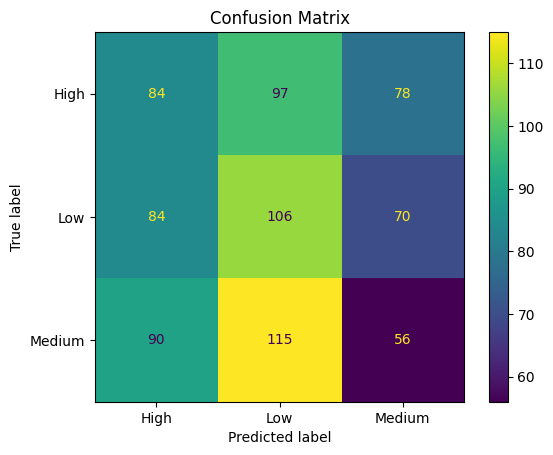

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [25]:
from sklearn.metrics import roc_auc_score

y_proba = model.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test,
    y_proba,
    multi_class='ovr'
)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.48423653569683855


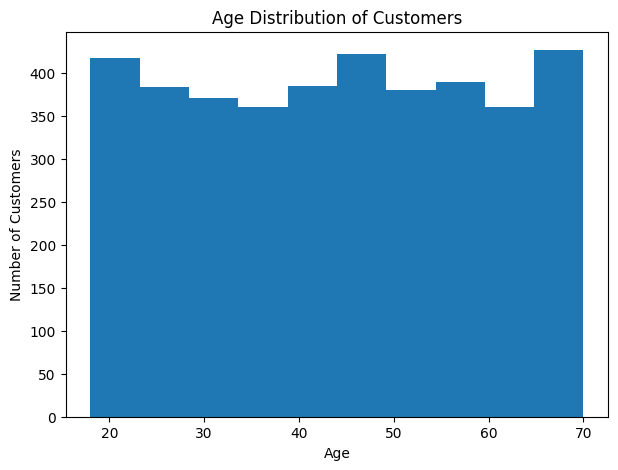

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.hist(df['Age'], bins=10)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

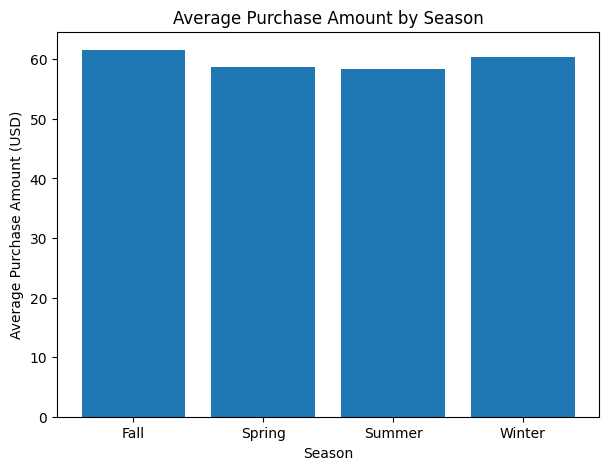

In [27]:
import matplotlib.pyplot as plt

season_purchase = df.groupby('Season')['Purchase Amount (USD)'].mean()

plt.figure(figsize=(7, 5))

plt.bar(season_purchase.index, season_purchase.values)

plt.title('Average Purchase Amount by Season')
plt.xlabel('Season')
plt.ylabel('Average Purchase Amount (USD)')

plt.show()

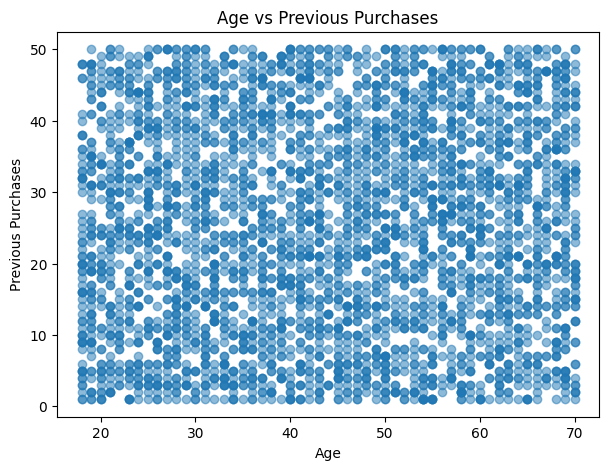

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    df['Age'],
    df['Previous Purchases'],
    alpha=0.5
)

plt.title('Age vs Previous Purchases')
plt.xlabel('Age')
plt.ylabel('Previous Purchases')

plt.show()

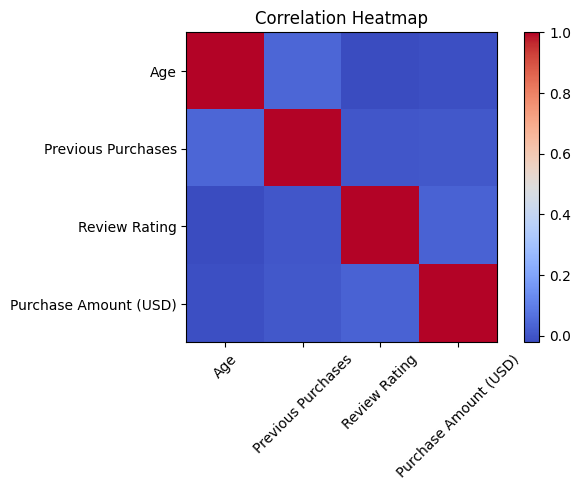

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

correlation = df[
    ['Age', 'Previous Purchases', 'Review Rating',
     'Purchase Amount (USD)']
].corr()

plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap='coolwarm')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

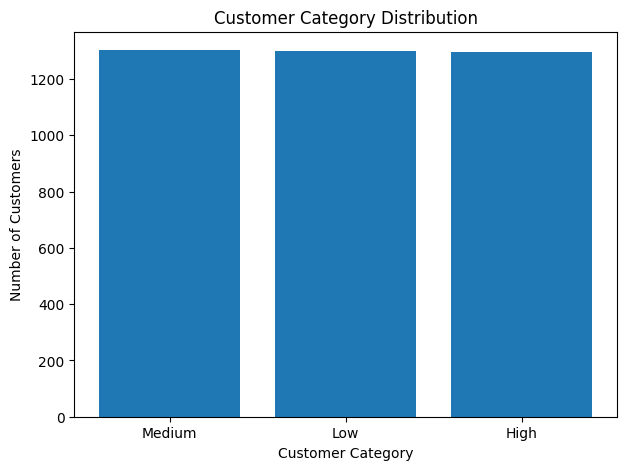

In [30]:
import matplotlib.pyplot as plt

category_counts = df['Customer_Category'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title('Customer Category Distribution')
plt.xlabel('Customer Category')
plt.ylabel('Number of Customers')

plt.show()

In [31]:
import joblib

joblib.dump(model, 'customer_category_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [32]:
from google.colab import files

files.download('customer_category_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load('customer_category_model.pkl')

st.title("Customer Category Prediction")
st.write("Predict customer category using customer behavior.")

st.subheader("Enter Customer Details")

age = st.number_input(
    "Age",
    min_value=18,
    max_value=100,
    value=30
)

previous_purchases = st.number_input(
    "Previous Purchases",
    min_value=0,
    max_value=100,
    value=10
)

review_rating = st.number_input(
    "Review Rating",
    min_value=1.0,
    max_value=5.0,
    value=3.5,
    step=0.1
)

frequency = st.selectbox(
    "Frequency of Purchases",
    df['Frequency of Purchases'].unique()
)

subscription = st.selectbox(
    "Subscription Status",
    df['Subscription Status'].unique()
)

if st.button("Predict Customer Category"):

    input_data = pd.DataFrame({
        'Age': [age],
        'Previous Purchases': [previous_purchases],
        'Review Rating': [review_rating],
        'Frequency of Purchases': [frequency],
        'Subscription Status': [subscription]
    })

    prediction = model.predict(input_data)

    st.success(f"Predicted Customer Category: {prediction[0]}")

Writing app.py


In [34]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load model and dataset
model = joblib.load('customer_category_model.pkl')
df = pd.read_csv('shopping_trends.csv')

st.title("Customer Category Prediction")
st.write("Predict customer category using customer behavior.")

st.subheader("Enter Customer Details")

age = st.number_input(
    "Age",
    min_value=18,
    max_value=100,
    value=30
)

previous_purchases = st.number_input(
    "Previous Purchases",
    min_value=0,
    max_value=100,
    value=10
)

review_rating = st.number_input(
    "Review Rating",
    min_value=1.0,
    max_value=5.0,
    value=3.5,
    step=0.1
)

frequency = st.selectbox(
    "Frequency of Purchases",
    df['Frequency of Purchases'].unique()
)

subscription = st.selectbox(
    "Subscription Status",
    df['Subscription Status'].unique()
)

if st.button("Predict Customer Category"):

    input_data = pd.DataFrame({
        'Age': [age],
        'Previous Purchases': [previous_purchases],
        'Review Rating': [review_rating],
        'Frequency of Purchases': [frequency],
        'Subscription Status': [subscription]
    })

    prediction = model.predict(input_data)

    st.success(f"Predicted Customer Category: {prediction[0]}")

Overwriting app.py


In [35]:
!ls -l app.py customer_category_model.pkl shopping_trends.csv

-rw-r--r-- 1 root root   1247 Oct  4 17:29 app.py
-rw-r--r-- 1 root root   4033 Oct  4 17:28 customer_category_model.pkl
-rw-r--r-- 1 root root 453248 Oct  4 17:06 shopping_trends.csv


In [36]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 40.4 MB/s eta 0:00:00


In [37]:
!streamlit run app.py &>/content/streamlit.log &

In [38]:
!cat /content/streamlit.log



2026-10-04 17:31:04.644 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.74.67.25:8501



In [39]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.9.3) ...
Setting up cloudflared (2026.9.3) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared tunnel --url http://localhost:8501

2026-10-04T17:33:31Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-04T17:33:31Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-04T17:33:37Z INF +--------------------------------------------------------------------------------------------+
2026-10-04T17:33:37Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-04T17:33:37Z INF |  https://sending-meyer-violations-soul.trycloudflare.c

In [ ]:
print("===== MODEL EVALUATION =====")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("ROC-AUC:", roc_auc)